Iteration 0: Best Fitness = 235.07
Iteration 50: Best Fitness = 173.91
Iteration 100: Best Fitness = 173.23
Iteration 150: Best Fitness = 173.17
Iteration 200: Best Fitness = 173.15
Iteration 250: Best Fitness = 173.15

Optimized Drone Route:
Point 1: [5. 5.]
Point 2: [ 0.19144422 57.89150682]
Point 3: [ 0.         59.99988771]
Point 4: [ 0.         60.00000015]
Point 5: [79.741381   59.99999995]
Point 6: [95. 95.]

Total Distance: 173.15
Status: Collision-free route found!


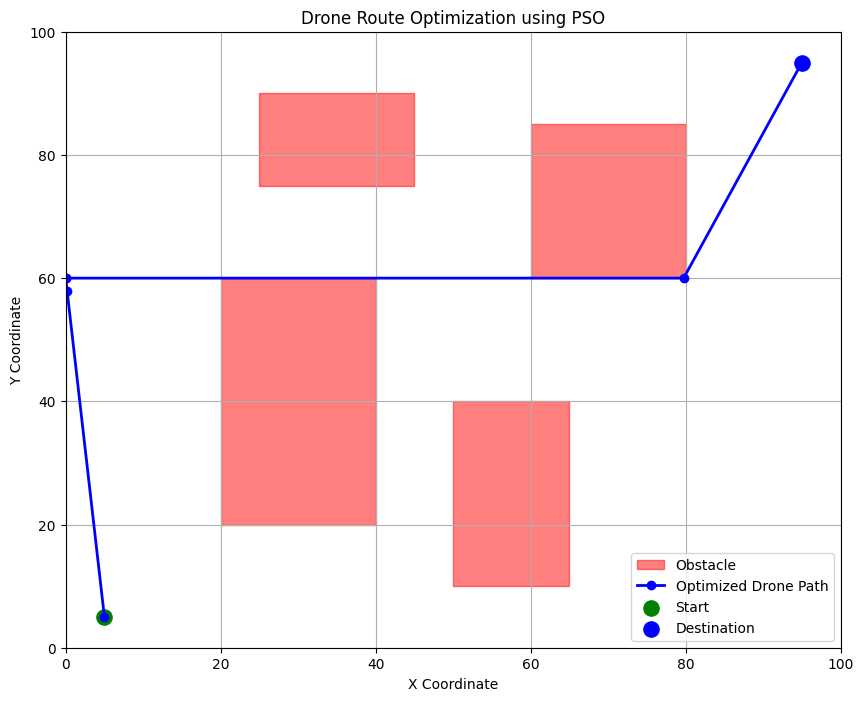

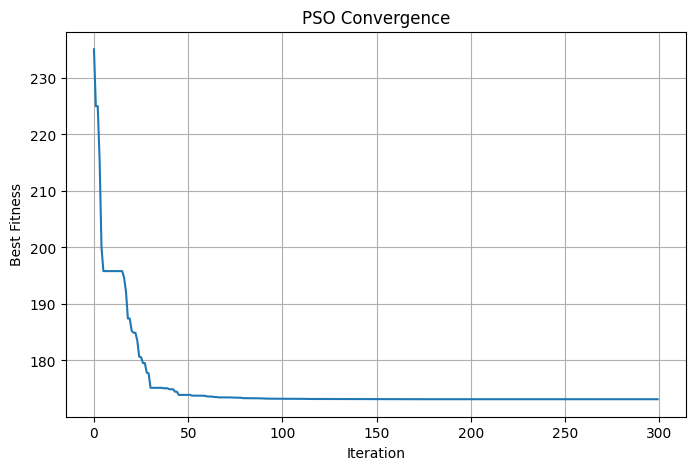

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------
# 1. DRONE ENVIRONMENT
# --------------------------------

START = np.array([5, 5])
GOAL = np.array([95, 95])

# Rectangular obstacles: [xmin, ymin, xmax, ymax]
obstacles = [
    [20, 20, 40, 60],
    [50, 10, 65, 40],
    [60, 60, 80, 85],
    [25, 75, 45, 90]
]

# Number of intermediate waypoints
N_WAYPOINTS = 4

# --------------------------------
# 2. PSO PARAMETERS
# --------------------------------

N_PARTICLES = 60
MAX_ITER = 300

W = 0.7 # Inertia weight
C1 = 1.5 # Cognitive coefficient
C2 = 1.5 # Social coefficient

DIM = N_WAYPOINTS * 2

LOWER = 0
UPPER = 100

# --------------------------------
# 3. COLLISION DETECTION
# --------------------------------

def is_inside(point, obstacle):
    xmin, ymin, xmax, ymax = obstacle

    return (
        xmin <= point[0] <= xmax and
        ymin <= point[1] <= ymax
    )


def collision_penalty(path):
    penalty = 0

    # Check every path segment
    for i in range(len(path) - 1):

        p1 = path[i]
        p2 = path[i + 1]

        # Sample points along the segment
        for t in np.linspace(0, 1, 60):

            point = p1 + t * (p2 - p1)

            for obstacle in obstacles:
                if is_inside(point, obstacle):
                    penalty += 1000

    return penalty


# --------------------------------
# 4. FITNESS FUNCTION
# --------------------------------

def fitness(position):

    waypoints = position.reshape(N_WAYPOINTS, 2)

    path = np.vstack((START, waypoints, GOAL))

    # Calculate total flight distance
    distance = 0

    for i in range(len(path) - 1):
        distance += np.linalg.norm(
            path[i + 1] - path[i]
        )

    # Calculate obstacle penalty
    penalty = collision_penalty(path)

    return distance + penalty


# --------------------------------
# 5. INITIALIZE PARTICLES
# --------------------------------

positions = np.random.uniform(
    LOWER, UPPER,
    (N_PARTICLES, DIM)
)

velocities = np.random.uniform(
    -5, 5,
    (N_PARTICLES, DIM)
)

personal_best = positions.copy()

personal_fitness = np.array([
    fitness(p) for p in positions
])

best_index = np.argmin(personal_fitness)

global_best = personal_best[best_index].copy()
global_fitness = personal_fitness[best_index]

history = []

# --------------------------------
# 6. PARTICLE SWARM OPTIMIZATION
# --------------------------------

for iteration in range(MAX_ITER):

    for i in range(N_PARTICLES):

        r1 = np.random.rand(DIM)
        r2 = np.random.rand(DIM)

        # Update velocity
        velocities[i] = (
            W * velocities[i]
            + C1 * r1 * (
                personal_best[i] - positions[i]
            )
            + C2 * r2 * (
                global_best - positions[i]
            )
        )

        # Update position
        positions[i] += velocities[i]

        # Keep particles within the search space
        positions[i] = np.clip(
            positions[i], LOWER, UPPER
        )

        current_fitness = fitness(positions[i])

        # Update personal best
        if current_fitness < personal_fitness[i]:

            personal_fitness[i] = current_fitness
            personal_best[i] = positions[i].copy()

        # Update global best
        if current_fitness < global_fitness:

            global_fitness = current_fitness
            global_best = positions[i].copy()

    history.append(global_fitness)

    if iteration % 50 == 0:
        print(
            f"Iteration {iteration}: "
            f"Best Fitness = {global_fitness:.2f}"
        )


# --------------------------------
# 7. GET OPTIMIZED DRONE ROUTE
# --------------------------------

best_waypoints = global_best.reshape(
    N_WAYPOINTS, 2
)

best_path = np.vstack((
    START,
    best_waypoints,
    GOAL
))

print("\nOptimized Drone Route:")
for i, point in enumerate(best_path):
    print(f"Point {i + 1}: {point}")

print("\nTotal Distance:",
      round(sum(
          np.linalg.norm(best_path[i + 1] - best_path[i])
          for i in range(len(best_path) - 1)
      ), 2))

if collision_penalty(best_path) == 0:
    print("Status: Collision-free route found!")
else:
    print("Status: No collision-free route found. Try more iterations.")


# --------------------------------
# 8. VISUALIZE THE ROUTE
# --------------------------------

plt.figure(figsize=(10, 8))

# Draw obstacles
for obstacle in obstacles:

    xmin, ymin, xmax, ymax = obstacle

    plt.fill(
        [xmin, xmax, xmax, xmin],
        [ymin, ymin, ymax, ymax],
        color='red',
        alpha=0.5,
        label='Obstacle' if obstacle == obstacles[0] else ""
    )

# Draw optimized path
plt.plot(
    best_path[:, 0],
    best_path[:, 1],
    'b-o',
    linewidth=2,
    markersize=6,
    label='Optimized Drone Path'
)

# Start and goal
plt.scatter(*START, color='green', s=120, label='Start')
plt.scatter(*GOAL, color='blue', s=120, label='Destination')

plt.title("Drone Route Optimization using PSO")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.grid(True)
plt.legend()
plt.show()


# --------------------------------
# 9. FITNESS CONVERGENCE GRAPH
# --------------------------------

plt.figure(figsize=(8, 5))

plt.plot(history)

plt.title("PSO Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")

plt.grid(True)
plt.show()
